In [1]:
from pathlib import Path
import pickle as pk
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
import numpy as np
from test_utils.evaluation_utils import overlapGrads_plot
from matplotlib import cycler 
from itertools import cycle
from matplotlib import cm
from matplotlib import colormaps
from matplotlib import colors
import pickle as pk

output=Path('./data_sync/paper_results/')
plt.rcParams.update({
    "font.size": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "figure.dpi": 300,
})

# Colores fijos para ini y maxL2
fixed_colors = {'maxL2':"#5DA5DA",
                'noSA':"#60BD68", 
                'real_25_modelG':"#EC9C33", 
                'real_25_modelY':"#D43030",
                'real_5_modelG':"#EC9C33", 
                'real_5_modelY':"#D43030"     
}

light_palette = [    
    "#5DA5DA",  # blue
    "#60BD68",  # green
    "#EC9C33",  # ochre"
    "#3F1818",  # pink
]
plt.rcParams["axes.prop_cycle"] = cycler(color=light_palette)
auto_colors = cycle(light_palette)

Resultados para: EGNN - 5


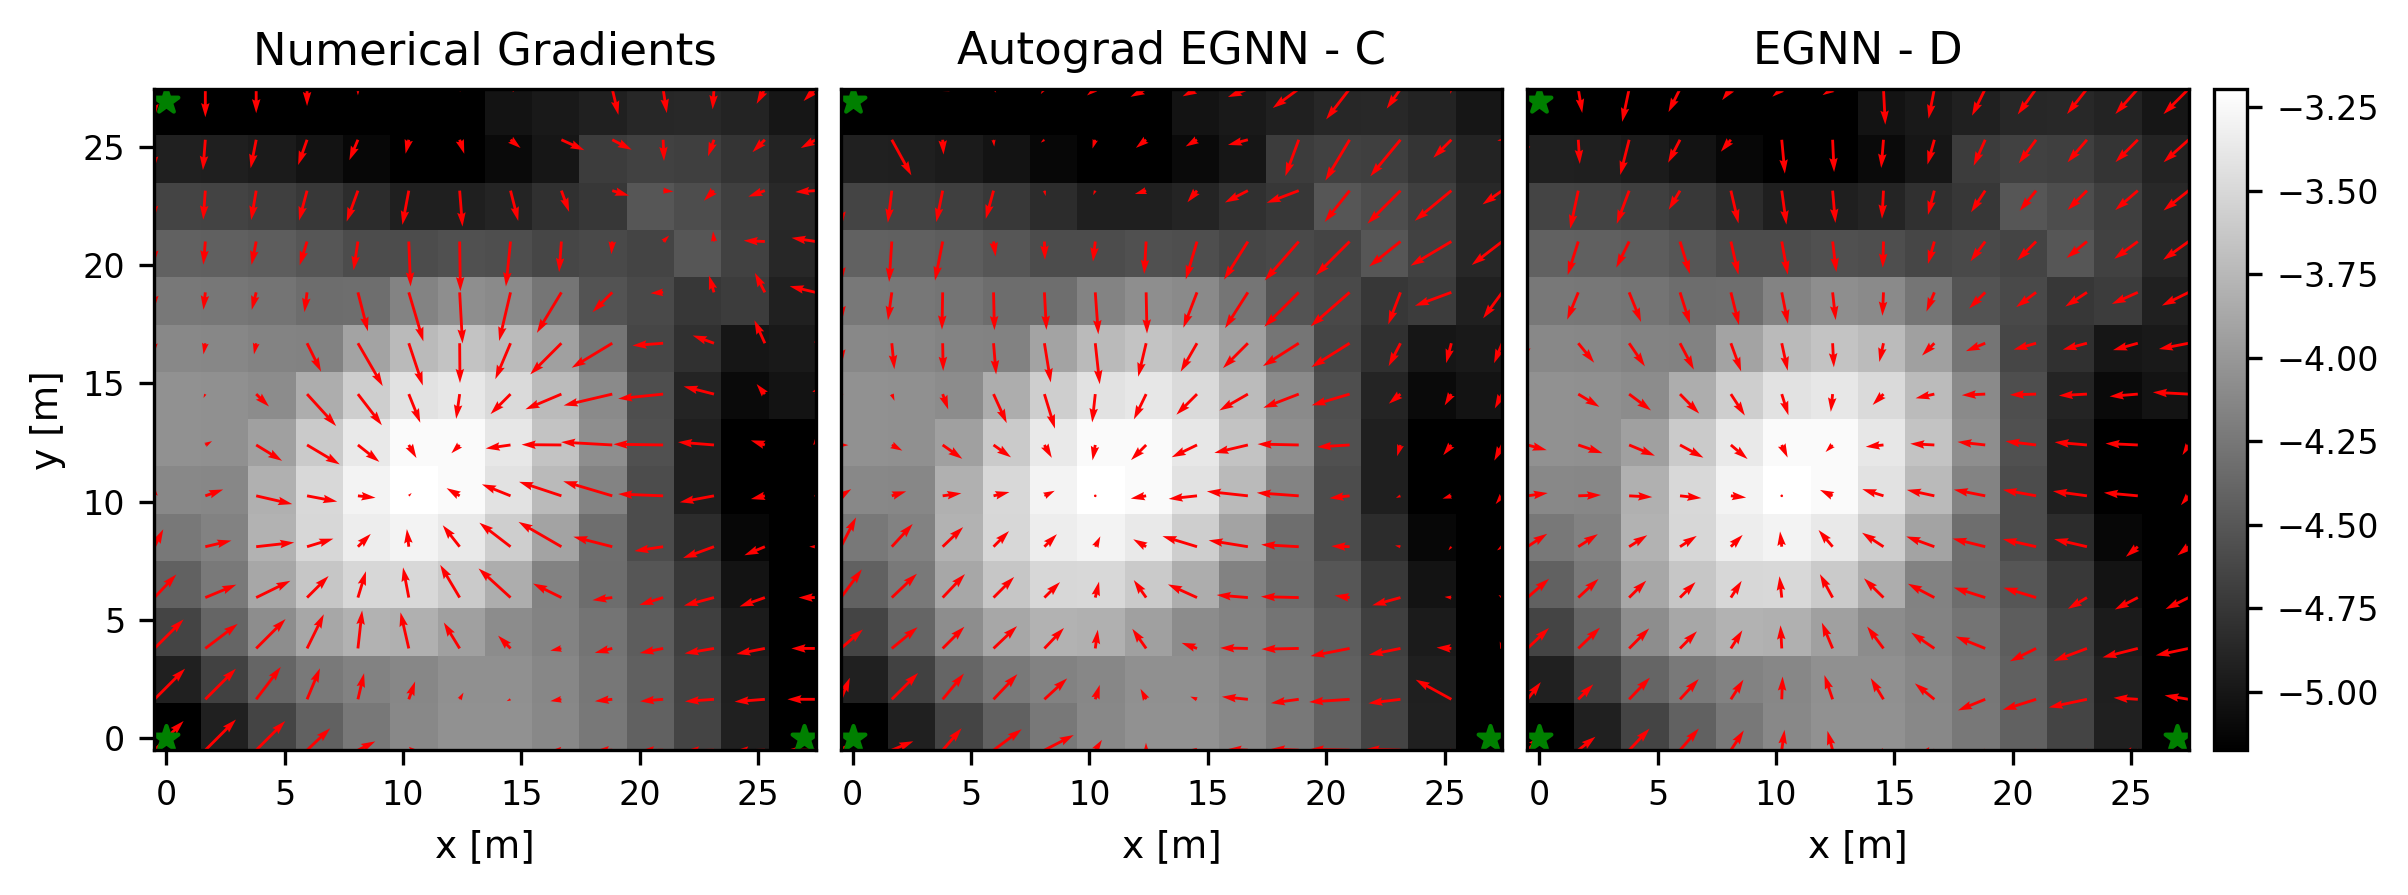

In [ ]:
####Gradients #######
# resultados={
#     'task_config':TA,
#     'comm_config':NA,
#     'net_id':net_id,
#     'c_mapCVXPY': c_mapCVXPY,
#     'grad_y': grad_y,
#     'grad_x':grad_x,
#     'x_eval':x,
#     'y_eval':y  
# }
def plot_gradients_comparison(TA, NA, grad_x, grad_y, x, y, grads_U_autograd, grads_V_autograd, grads_U_model, grads_V_model, c_mapCVXPY, name, output:Path):
    output.mkdir(parents=True, exist_ok=True)
    # --- Gráficos
    X, Y = np.meshgrid(x, y)

    #fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    fig = plt.figure(figsize=(9, 3), )
    gs = GridSpec(1, 4, width_ratios=[1, 1, 1, 0.05], wspace=0.05)

    ax0 = fig.add_subplot(gs[0, 0])
    ax1 = fig.add_subplot(gs[0, 1])
    ax2 = fig.add_subplot(gs[0, 2])
    cax = fig.add_subplot(gs[0, 3])  
    # --- Primer plot: Gradientes verdaderos
    overlapGrads_plot(task_config=TA, comm_config=NA, net_id=3, c_map=c_mapCVXPY, x=x, y=y, grid_grads_U=grad_x, grid_grads_V=grad_y, title="Numerical Gradients", ax=ax0, legend=False)
    # --- Segundo plot: AutoGradientes del modelo
    overlapGrads_plot(task_config=TA, comm_config=NA, net_id=3, c_map=c_mapCVXPY, x=x, y=y, grid_grads_U=grads_U_autograd, grid_grads_V=grads_V_autograd, title="Autograd EGNN - C", ax=ax1, legend=False)
    # --- Tercer plot: Gradientes del modelo
    im1=overlapGrads_plot(task_config=TA, comm_config=NA, net_id=3, c_map=c_mapCVXPY, x=x, y=y, grid_grads_U=grads_U_model, grid_grads_V=grads_V_model, title="EGNN - D", ax=ax2, legend=False)

    #divider1 = make_axes_locatable(axs[2])
    #cax1 = divider1.append_axes("right", size="5%", pad=0.05)
    # Obtener las posiciones de los 3 subplots
    pos0 = ax0.get_position()
    pos1 = ax1.get_position()
    pos2 = ax2.get_position()

    # Calcular la altura mínima común
    min_bottom = min(pos0.y0, pos1.y0, pos2.y0)
    max_top = max(pos0.y1, pos1.y1, pos2.y1)
    ax0.set_ylabel('y [m]')
    for ax in [ax1, ax2]:
        ax.set_yticks([])
    # Aplicar exactamente el mismo alto a la colorbar
    cax.set_position([cax.get_position().x0, min_bottom,
                    cax.get_position().width, max_top - min_bottom])
    cbar=plt.colorbar(im1, cax=cax)

    #cbar.ax.tick_params(labelsize=7)   # ← tamaño de labels

    #plt.tight_layout()
    plt.savefig(output/f'heatmap_gradients_{name}.pdf', format='pdf', bbox_inches='tight', dpi=300)
    plt.show()
    plt.close(fig)
    

with open(output / "prueba_gradientes.pkl", 'rb') as f:
    resultados=pk.load(f)

name_list= [k for k in resultados.keys() if k not in ['task_config','comm_config','grad_y','grad_x','x_eval','y_eval','c_mapCVXPY','net_id']]
for name in name_list:
    print(f"Resultados para: {name}")
    TA=resultados['task_config']
    NA=resultados['comm_config']
    grad_y=resultados['grad_y']
    grad_x=resultados['grad_x']
    x=resultados['x_eval']
    y=resultados['y_eval']
    grads_U_autograd=resultados[name]['gradsUautograd']
    grads_V_autograd=resultados[name]['gradsVautograd']
    grads_U_model=resultados[name]['gradsUmodel']
    grads_V_model=resultados[name]['gradsVmodel']
    c_mapCVXPY=resultados['c_mapCVXPY']
    plot_gradients_comparison(TA, NA, grad_x, grad_y, x, y, grads_U_autograd, grads_V_autograd, grads_U_model, grads_V_model, c_mapCVXPY, name, output)



Variants found in time results: ['maxL2', 'noSA', 'real_5_modelY', 'real_5_modelG']


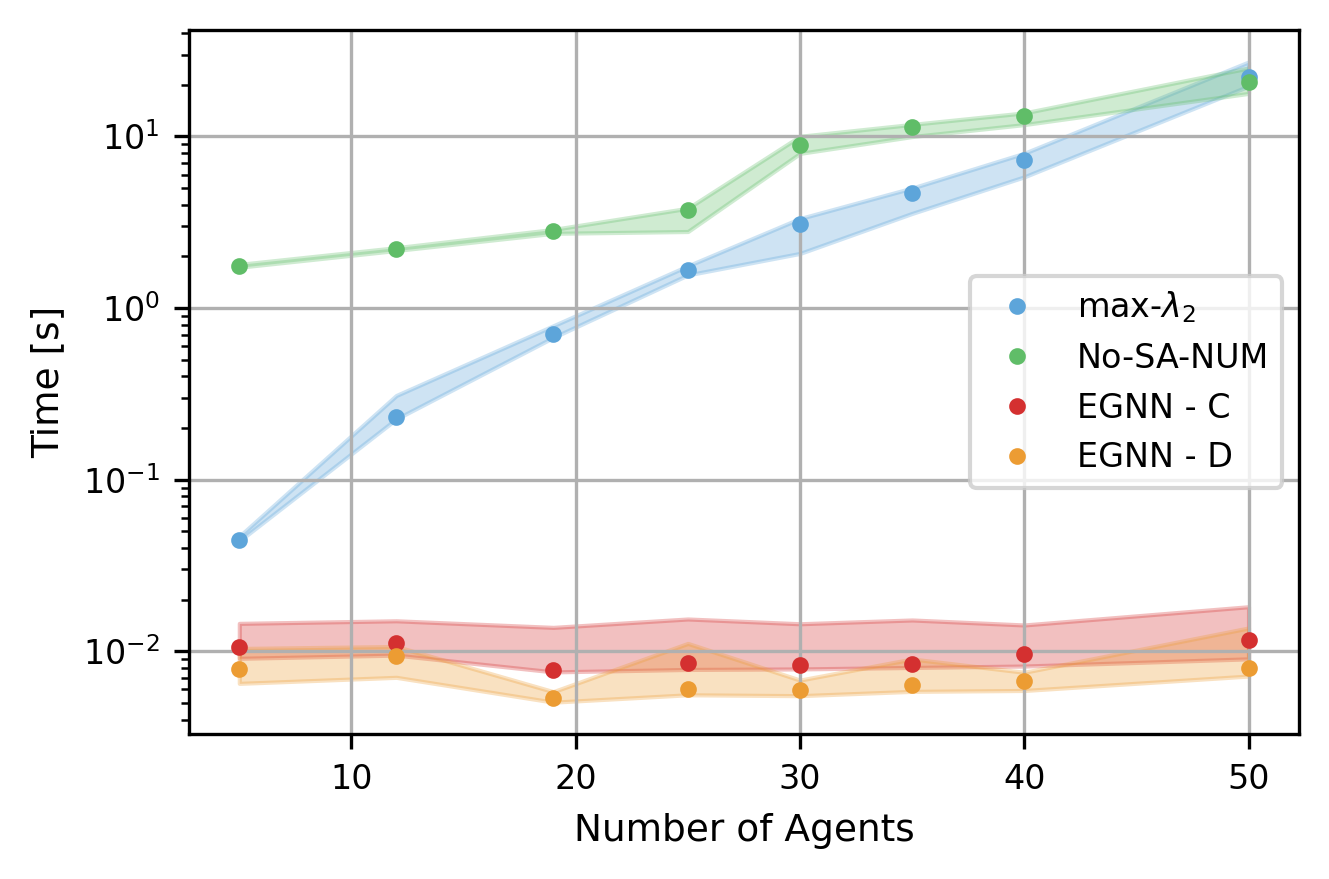

In [6]:
#### tiempos vs num agents#####
def plot_time_per_total_agents(time_per_total_agents, variants, output:Path):
    
    plt.figure(figsize=(4.5,3))  # <-- tamaño de la imagen

    labels=[v for v in variants]
    labelsplt = [label.replace('real_5_modelY','EGNN - C').replace('real_5_modelG','EGNN - D').replace('noSA','No-SA-NUM').replace('maxL2',f"max-$\lambda_2$") for label in labels]
    dict_labels = {v: labelsplt[i] for i,v in enumerate(variants)}

    for var, num_agents_list in time_per_total_agents.items():
        if var not in variants:
            continue
        num_agents=num_agents_list.keys()
        values=[time_per_total_agents[var][num] for num in num_agents]
        means=[np.mean(v) for v in values]
        stds=[np.std(v) for v in values]
        q50   = [np.percentile(v, 50) for v in values]
        q25   = [np.percentile(v, 10) for v in values]
        q75   = [np.percentile(v, 90) for v in values]
        lower=[means_i - stds_i for means_i, stds_i in zip(means, stds)]
        if var == 'real_5_modelY':
            plt.semilogy(list(num_agents_list.keys()), q50, '.', label=dict_labels[var], color=fixed_colors[var])
        else:
            plt.semilogy(list(num_agents_list.keys()), q50, '.', label=dict_labels[var], color=fixed_colors[var])
        
        plt.fill_between(list(num_agents_list.keys()),
                        q25,
                        q75, alpha=0.3, color=fixed_colors[var])
        
    plt.tick_params(axis='both')

    plt.xlabel("Number of Agents")
    plt.ylabel("Time [s]")
    plt.grid()
    #plt.title(f"Mean Time vs Total Agents ({experimentType.capitalize()} Experiment)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(output/"time_per_total_agents.pdf")
    plt.show()
  
with open(output / "resultados_tiempos.pkl", 'rb') as f:
    time_per_total_agents=pk.load(f)

variants= [k for k in time_per_total_agents.keys() ]#if k != 'noSA' ]
print("Variants found in time results:", variants)
plot_time_per_total_agents(time_per_total_agents, variants, output)


Referencias detectadas: {'maxL2'}
Variantes detectadas: {'real_25_modelY', 'real_25_modelG', 'noSA', 'maxL2'}
grupo:  INI


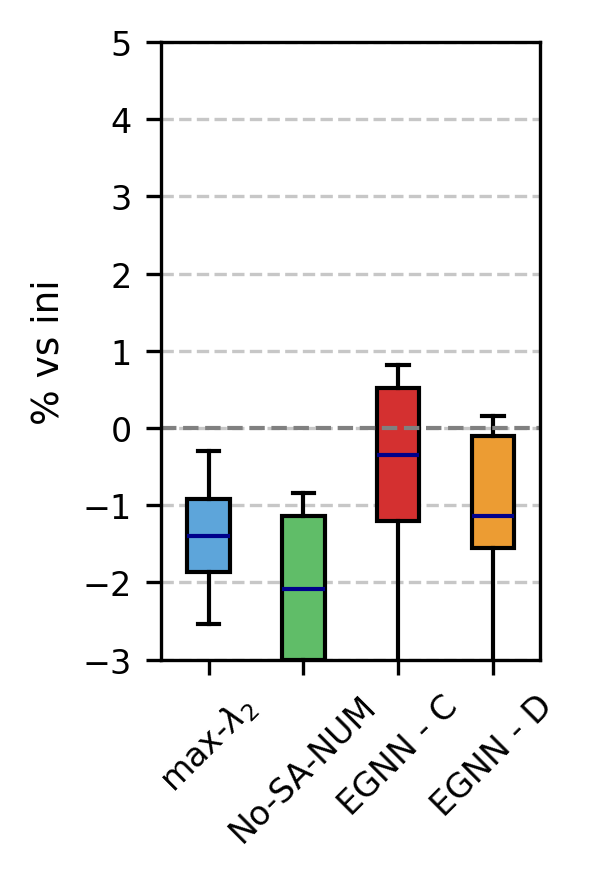

grupo:  ref


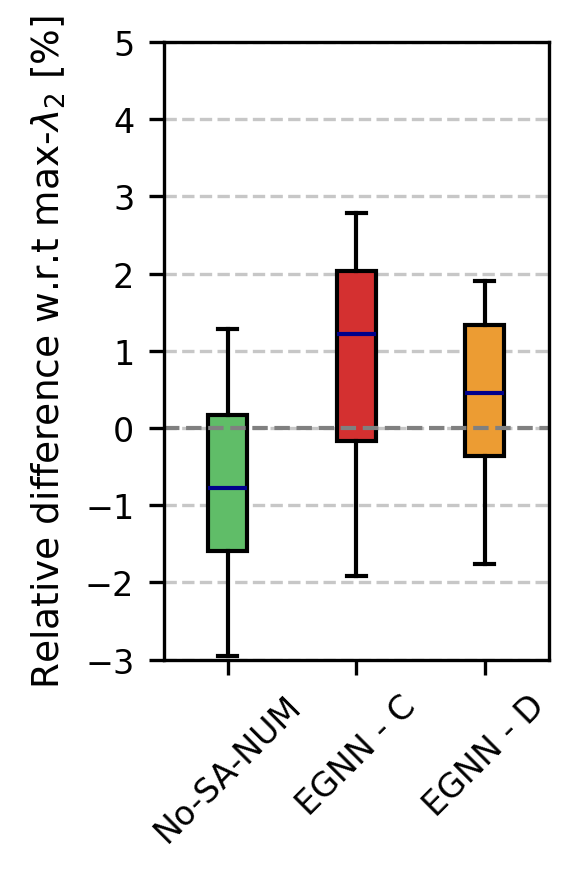

grupo:  time_


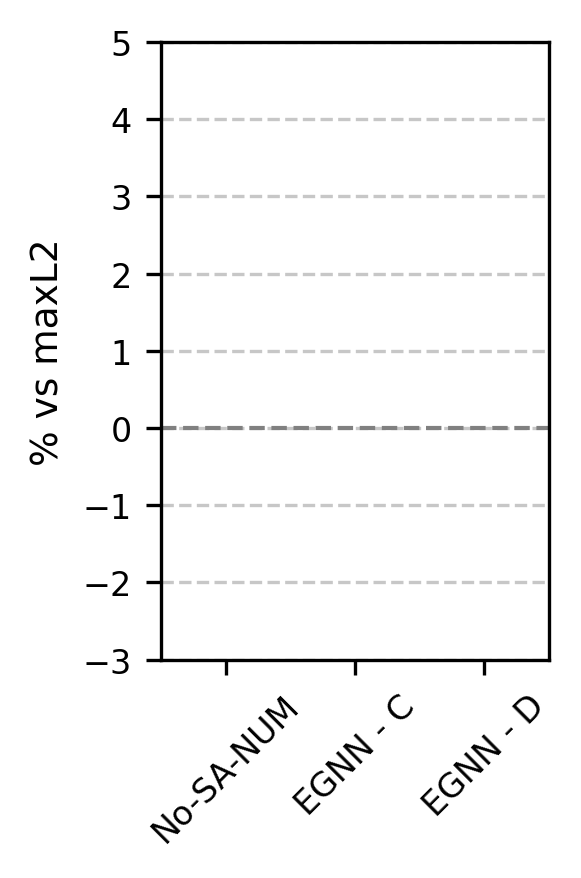

In [10]:
### Boxplot de P por variante ###


def plot_comparison_variants(results, output_path, model):
    variants = set()
    ref_variants = set()
    for k in results:
        if k.startswith('mnf-ini-'):
            variant = k.replace('mnf-ini-', '')
            variants.add(variant)
        elif k.startswith('mnf-'):
            # Extraer el nombre de la referencia
            # Forma: mnf_<ref>_<variant>
            parts = k.split('-')
            if len(parts) >= 3:
                ref_variants.add(parts[1])
                variants.add(parts[2])
    
    print("Referencias detectadas:", ref_variants)
    print("Variantes detectadas:", variants)
    # Grupos a plotear
    plots_num = 2 * len(ref_variants) + 1
    grupos = {
        'INI': {'prefix': 'mnf-ini-', 'ylabel': '% vs ini', 'titulo': 'Mejora sobre configuración inicial'}}
    for ref in ref_variants:
        grupos[f'ref']= {'prefix': f'mnf-{ref}-', 'ylabel': f'Relative difference w.r.t max-$\lambda_2$ [%]', 'titulo': f'Relative difference w.r.t max-$\lambda_2$ [%]'}
        grupos[f'time_']= {'prefix': f'time-', 'ylabel': f'% vs {ref}', 'titulo': f"Relative difference w.r.t max-$\lambda_2$ [%]"}
    
    
    #fig, ax = plt.subplots(plots_num, 1, figsize=(10, 12))
  # Colores consistentes para todas las variantes
    auto_colors = cycle(light_palette)
    variant_colors = {}
    for label in sorted(variants):
        if label in fixed_colors:
            variant_colors[label] = fixed_colors[label]
        else:
            variant_colors[label] = next(auto_colors)

    # Plot
    for i, (grupo, props) in enumerate(grupos.items()):
        print('grupo: ', grupo)
        fig, ax = plt.subplots(figsize=(2, 3))
        prefix = props['prefix']
        keys = [k for k in results if k.startswith(prefix)]
        if not keys:
            print(f"No data for {grupo}")
            continue

        data = [results[k] for k in keys]
        labels = [k.replace(prefix, '') for k in keys]
        labelsplt = [label.replace(model+'_modelY','EGNN - C').replace(model+'_modelG','EGNN - D').replace('noSA','No-SA-NUM').replace('maxL2',f"max-$\lambda_2$")  for label in labels]
        colores = [variant_colors[label] for label in labels]

        bplot = ax.boxplot(data, patch_artist=True, showfliers=False,
                              medianprops={'color': 'darkblue'})
        ax.axhline(0, color='gray', linestyle='--', linewidth=1)
        ax.set_facecolor("white")
        ax.set_ylabel(props['ylabel'])
        ax.set_ylim(-3.0,5.0)
        #ax.set_title(props['titulo'])
        ax.set_xticks(range(1, len(labels) + 1))
        ax.set_xticklabels(labelsplt,rotation=45)
        ax.grid(axis='y', linestyle='--', alpha=0.7)

        for patch, color in zip(bplot['boxes'], colores):
            patch.set_facecolor(color)

        plt.tight_layout()
        plt.savefig(output_path / f'{model}_boxplots{grupo}_{experimento}.pdf')
        plt.show()
        plt.close(fig)
    
experimento="real25_20251230_101159"      
model="real_25"
with open(output / f'boxplot_data_{experimento}_Pvalues.pkl', 'rb') as f:
    results=pk.load(f)
plot_comparison_variants(results=results, output_path=output, model=model)

TypeError: plot_comparison_variants() got an unexpected keyword argument 'ax'

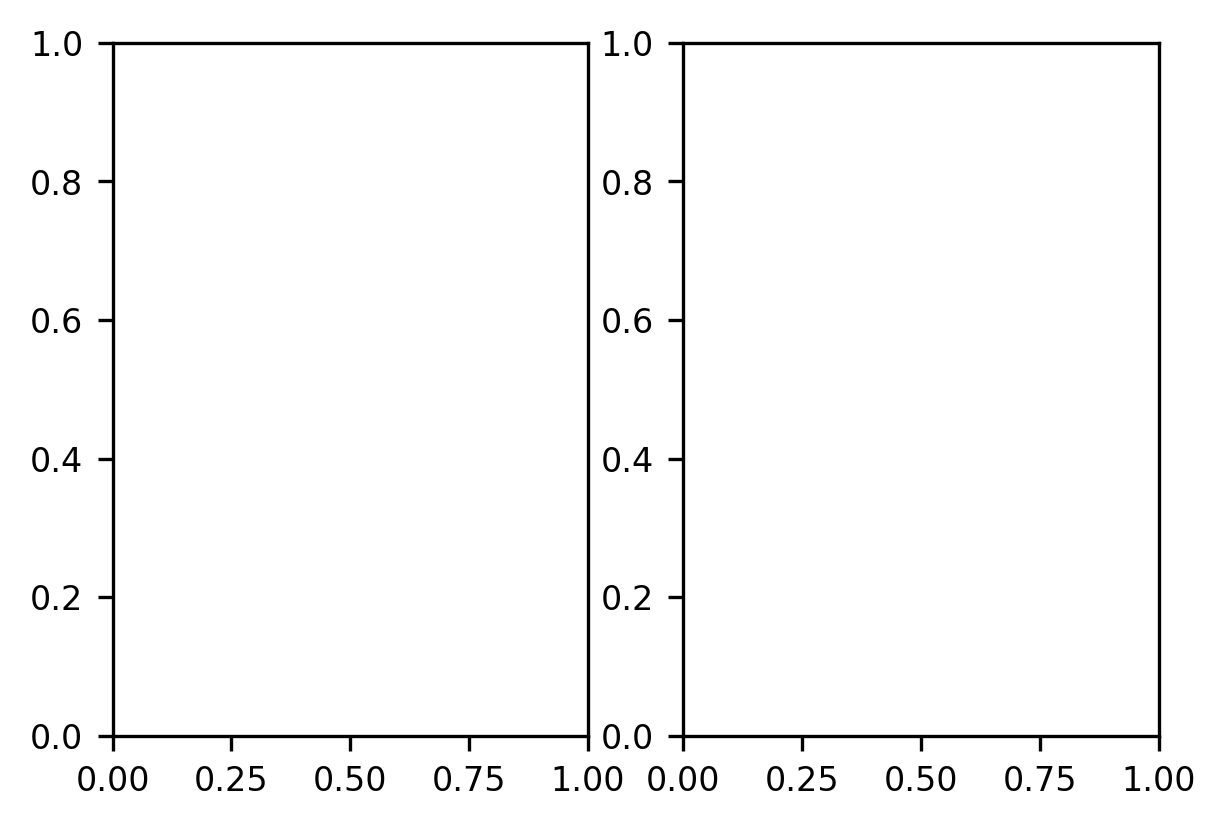

In [3]:
experimento1="real25_20251215_105547-25"      
experimento="real25_20251127_132415-35"

model="real_25"
with open(output / f'boxplot_data_{experimento1}_Pvalues.pkl', 'rb') as f:
    results1=pk.load(f)
with open(output / f'boxplot_data_{experimento}_Pvalues.pkl', 'rb') as f:
    results=pk.load(f)
fig , ax =  plt.subplots(1,2,figsize=(4.5, 3))
plot_comparison_variants(results=results1, output_path=output, model=model, ax=ax[0])

plot_comparison_variants(results=results, output_path=output, model=model, ax=ax[1])

NameError: name 'variants' is not defined

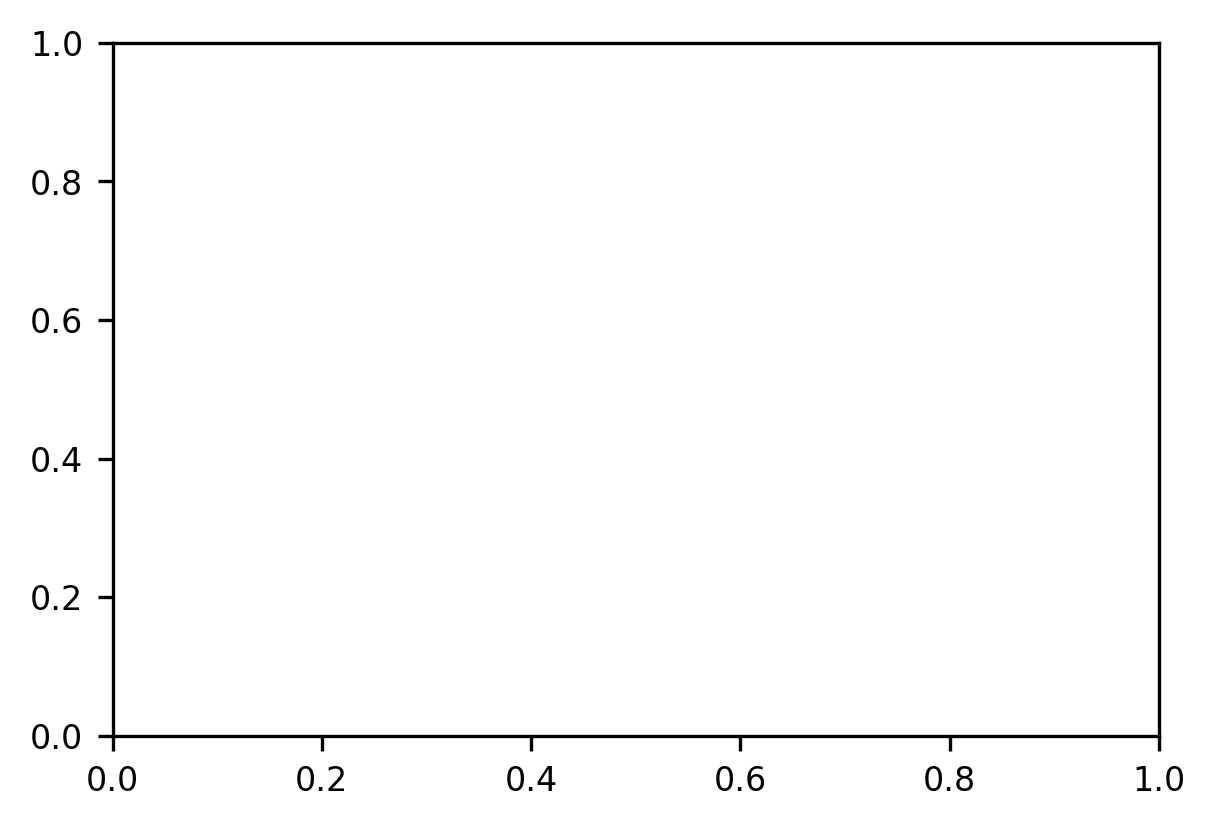

In [ ]:
#### Ak values###
with open(output/f'boxplot_data_{experimento}_ak_values.pkl', 'rb') as f:
    diff_l2=pickle.load(f)

def plot_ak_values(diff_L2, output):
    auto_colors = cycle(light_palette)  
    box_plot=[np.concatenate(diff_l2[key]) for key in diff_l2.keys()] 
    fig, ax = plt.subplots(figsize=(4.5, 3))
    labels = [k for k in diff_l2.keys() if k != 'maxL2']
    labelsplt = [label.replace('real_25_modelY','EGNN - C').replace('real_25_modelG','EGNN - D') for label in labels]
    variant_colors = {}
    auto_colors = cycle(light_palette)
    for label in sorted(variants):
        if label in fixed_colors:
            variant_colors[label] = fixed_colors[label]
        else:
            variant_colors[label] = next(auto_colors)
    
    colores = [variant_colors[label] for label in labels]

    # Boxplot
    bplot = ax.boxplot(box_plot, patch_artist=True, showfliers=False,
                        medianprops={'color': 'darkblue'})
    ax.axhline(0, color='gray', linestyle='--', linewidth=1)
    ax.set_facecolor("white")
    ax.set_ylabel(f'Relative difference w.r.t max $\lambda_2$ [%]')
    ax.set_xticks(range(1, len(labels) + 1))
    ax.set_xticklabels(labelsplt, fontsize=11)
    ax.grid(axis='y', linestyle='--', alpha=0.7)

    for patch, color in zip(bplot['boxes'], colores):
        patch.set_facecolor(color)
    for key in diff_l2.keys():
        print(f"Variant: {key}, Diff L2: {np.mean(diff_l2[key])}")
        
    plt.tight_layout()
    plt.savefig(output / f'{model}_boxplotsAk.pdf')
    plt.show()
    plt.close(fig)
  
with open(output/f'boxplot_data_{experimento}_ak_values.pkl', 'rb') as f:
    diff_l2=pk.load(f)  

plot_ak_values(diff_L2=diff_l2, output=output)

In [16]:
folder="./data_sync/resultados/20251217_192309-50/processed_results_20251223_153543"
#20251215_153049\processed_results_20251215_154625
with open(Path(folder)/"processed_dynamic.pkl", "rb") as f:
    log_data = pk.load(f)
    

model='real_25'
print(len(log_data[model+'_modelY'][0]))
var=[k for k in log_data.keys() if model in k and model]
print(var)
titles = {v:v.replace(model+'_modelY','EGNN - C').replace(model+'_modelG','EGNN - D') for v in var}
    
plt.figure(figsize=(4.5, 3))
for v in var:
    print(f"{v}: {len(log_data[v])} experiments")

    data=np.array(log_data[v])  # shape (n_experiments, n_steps)
    steps = range(data.shape[1])
    mean = np.mean(data, axis=0)
    std = np.std(data, axis=0)
    data = (mean, std)
    plt.plot(steps, data[0], label=titles[v], color=fixed_colors.get(v))
    plt.fill_between(steps,
                        data[0] - data[1],
                        data[0] + data[1],
                        alpha=0.2, color=fixed_colors.get(v))
ylabel="Relative error w.r.t. no-SA-NUM [%]"
xlabel="Step"
   
plt.axhline(y=0, color='gray', linestyle='--', linewidth=1)  # línea horizontal en 0
plt.xlabel(xlabel)
plt.ylabel(ylabel)
plt.xticks(np.arange(0, len(steps), step=4))
#plt.ylim(*ylim)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(output / f'{model}noSAerror_dynamic.pdf')
plt.close()

21
['real_25_modelY', 'real_25_modelG']
real_25_modelY: 9 experiments
real_25_modelG: 9 experiments
